# CNN-Baseline CNN with more epochs and callbacks
**Authors:** Kai Henrik Herbst & Bell Wassim

### 1. Data Loading and Preprocessing
Load the dataset and perform the necessary preprocessing.

In [1]:
# Import the data loading and preprocessing function from our utility script
# Note: Ensure the .py file is in the same directory
from data_prep import load_stl10_data

# Load the dataset. The function handles downloading, splitting (80/20), 
# resizing to 96x96, normalizing, and one-hot encoding the labels.
ds_train, ds_val, ds_test = load_stl10_data()

2026-03-22 09:27:26.381855: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-22 09:27:27.793669: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-22 09:27:30.507058: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


2026-03-22 09:27:37.511353: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:02:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-22 09:27:37.770013: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


### 2. Network Creation (Baseline Model with more epochs and callbacks)
Here we define the architecture of our Baseline CNN with more epochs and callbacks. We use a stack of Conv2D and MaxPooling2D layers for feature extraction, followed by Dense layers for classification (its the same architecture as for the Baseline Model).

In [2]:
import keras
from keras import layers

# 1.Feature learning part
inputs = keras.Input(shape=(96, 96, 3))
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)

# 2.Classification Part
x = layers.Flatten()(x)
outputs = layers.Dense(10, activation="softmax")(x)

model_baseline_extended = keras.Model(inputs=inputs, outputs=outputs, name="Baseline_CNN_Extended")

model_baseline_extended.summary()

Model: "Baseline_CNN_Extended"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │       512,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 605,258 (2.31 MB)

 Trainable params: 605,258 (2.31 MB)

 Non-trainable params: 0 (0.00 B)

No architecture visualisation, because it is the same as for the baseline model.

### 3. Model Training
First, we compile the model, specifying the optimiser and loss function. Then, we add the callbacks and increase the epochs to 30, before training it on our preprocessed training data. We use the validation data to monitor the model's performance on unseen data and check for overfitting.

In [4]:
#Compile the model with the RMSprop optimizer, categorical crossentropy loss, and accuracy metric
model_baseline_extended.compile(
    optimizer='rmsprop',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [5]:
# Define callbacks for training: ModelCheckpoint to save the best model, and EarlyStopping to prevent overfitting
callbacks = [
    # Save the best model based on validation loss during training
    keras.callbacks.ModelCheckpoint(
        filepath="models/02_2_Baseline_CNN_Extended.keras",
        save_best_only=True,
        monitor="val_loss"),
    
    # Stop the training if the validation loss does not improve for 5 epochs,
    # and automatically load the weights of the best epoch.
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True)
]

In [6]:
# Train the model for 30 epochs with the defined callbacks
print("Starting the extended training process.")
history_baseline_ext = model_baseline_extended.fit(
    ds_train,
    epochs=30,  # Increased to 30 epochs
    validation_data=ds_val,
    callbacks=callbacks
)

Starting the extended training process.
Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 175ms/step - accuracy: 0.2410 - loss: 2.1252 - val_accuracy: 0.3350 - val_loss: 1.8107
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 243ms/step - accuracy: 0.4050 - loss: 1.6436 - val_accuracy: 0.4090 - val_loss: 1.7813
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 295ms/step - accuracy: 0.4845 - loss: 1.4022 - val_accuracy: 0.5800 - val_loss: 1.1631
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 279ms/step - accuracy: 0.5767 - loss: 1.2056 - val_accuracy: 0.5950 - val_loss: 1.0819
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 241ms/step - accuracy: 0.6220 - loss: 1.0290 - val_accuracy: 0.6670 - val_loss: 0.8763
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 254ms/step - accuracy: 0.7095 - loss: 0.8435 - val_accuracy: 0.7870 - val_loss: 0.6291
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 237ms/step - accuracy: 0.7730 - loss: 0.6757 - val_accuracy: 0.8280 - val_loss: 0.5433
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 235ms/step - ac

We visualize the training and validation progress to monitor the model's learning behavior. These plots help identify if the model has converged, if the number of epochs was sufficient, and whether there are signs of overfitting or underfitting during the extended 30-epoch run.

In [7]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

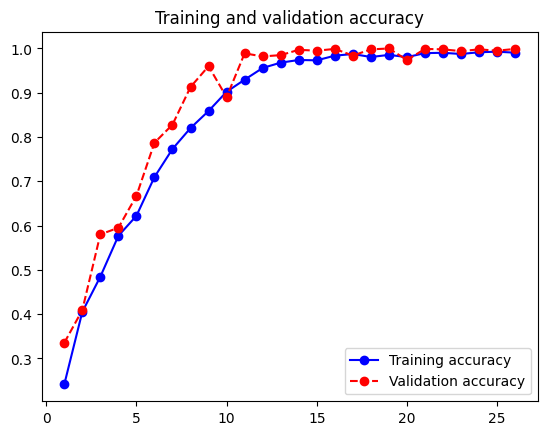

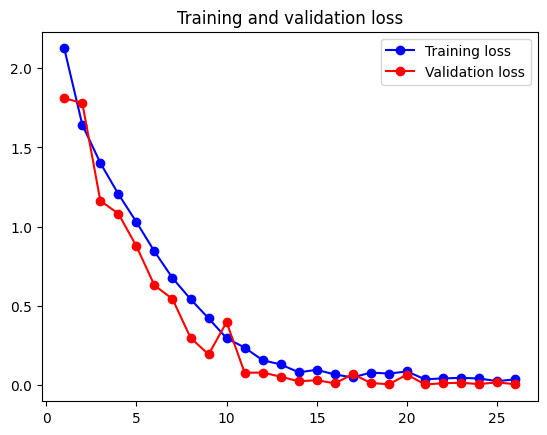

In [8]:
# After training, we can plot the training history to visualize the performance over epochs
plot(history_baseline_ext)

### 4. Evaluation
To determine the generalization capability of our extended baseline model, we evaluate it using the test dataset (`ds_test`). Since these images were neither used for training nor for validation, the results provide an unbiased estimate of the model's performance in a real-world scenario.

In [9]:
# Evaluate the trained extended baseline model on the unseen test dataset
print("Evaluating the model on the test dataset...")
test_loss, test_accuracy = model_baseline_extended.evaluate(ds_test)

print(f"\nFinal Test Loss: {test_loss:.3f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.3f}%")

Evaluating the model on the test dataset...
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.5269 - loss: 3.7995

Final Test Loss: 3.800
Final Test Accuracy: 52.688%


### 5. Result of Model 2
The results of this extended training phase demonstrate that simply increasing the number of epochs does not resolve the core performance issues. While the test accuracy slightly improved to **52.7%**, the model now suffers from **severe overfitting**.

**Key Observations & Interpretation:**
* **Generalization Failure:** We observe a nearly perfect accuracy (~99.9%) on both the training and validation sets, contrasted by a poor test accuracy of ~52.7%. This massive discrepancy is a textbook example of **Generalization Failure**: the network has successfully "memorized" the specific training and validation samples instead of learning abstract, transferable features.
* **Confidence Error (Loss 3.8):** The alarmingly high Test Loss of **3.8** indicates that the model is making incorrect predictions with extremely high confidence. This suggests the decision boundaries have become overly complex and tailored to the training noise.
* **Structural Bottleneck:** We hypothesize that the baseline architecture lacks the **Representational Capacity** (depth and filter variety) required to extract hierarchical abstractions (e.g., distinguishing fur patterns from mechanical parts) in the 96x96 pixel space of STL-10. The network takes the "easy route" of memorizing pixels because it lacks the depth to build complex concepts.

**Justification for Model 3:**
Before applying restrictive regularization (like Dropout), we must first increase the model's **Learning Capacity**. In the next step, we will design a **Deeper Architecture** by stacking multiple convolutional layers. This structural change aims to provide the network with the "tools" it needs to learn robust, hierarchical patterns before we force it to generalize.